In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [13]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

# ====================
# データ読み込み
# ====================

df = pd.read_csv("/kaggle/input/datasets/sakoshota/dataset-3/ETTh1.csv")

df["date"] = pd.to_datetime(df["date"])

# ====================
# 時間特徴量
# ====================

df["hour"] = df["date"].dt.hour

# ====================
# ラグ特徴量
# ====================

df["OT_lag1"] = df["OT"].shift(1)
df["OT_lag3"] = df["OT"].shift(3)
df["OT_lag24"] = df["OT"].shift(24)

# ====================
# 3時間後予測
# ====================

df["target"] = df["OT"].shift(-3)

# ====================
# 欠損除去
# ====================

df = df.dropna()

# ====================
# 特徴量
# ====================

features = [
    "HUFL",
    "HULL",
    "MUFL",
    "MULL",
    "LUFL",
    "LULL",
    "hour",
    "OT_lag1",
    "OT_lag3",
    "OT_lag24"
]

X = df[features]
y = df["target"]

# ====================
# 時系列分割
# ====================

split_idx = int(len(df) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

# ====================
# RandomForest
# ====================

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# ====================
# 予測
# ====================

pred = model.predict(X_test)

# ====================
# 評価
# ====================

mae = mean_absolute_error(y_test, pred)

rmse = np.sqrt(
    mean_squared_error(y_test, pred)
)

print("MAE :", mae)
print("RMSE:", rmse)
df.describe()

MAE : 0.8837494475162229
RMSE: 1.225924773172595


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT,hour,OT_lag1,OT_lag3,OT_lag24,target
count,17393,17393.000000,17393.000000,17393.000000,17393.000000,17393.000000,17393.000000,17393.000000,17393.000000,17393.000000,17393.000000,17393.000000,17393.000000
mean,2017-06-29 08:00:00,7.377972,2.241487,4.303550,0.881365,3.065614,0.855944,13.314577,11.496579,13.315079,13.315936,13.330088,13.312781
min,2016-07-02 00:00:00,-22.705999,-4.756000,-25.087999,-5.934000,-1.188000,-1.371000,-4.080000,0.000000,-4.080000,-4.080000,-4.080000,-4.080000
25%,2016-12-30 04:00:00,5.827000,0.737000,3.305000,-0.284000,2.315000,0.670000,6.964000,5.000000,6.964000,6.964000,6.964000,6.964000
50%,2017-06-29 08:00:00,8.774000,2.210000,5.970000,0.959000,2.833000,0.975000,11.396000,11.000000,11.396000,11.396000,11.396000,11.396000
75%,2017-12-27 12:00:00,11.788000,3.684000,8.635000,2.203000,3.625000,1.218000,18.079000,17.000000,18.079000,18.079000,18.079000,18.009001
max,2018-06-26 16:00:00,23.643999,10.114000,17.341000,7.747000,8.498000,3.046000,46.007000,23.000000,46.007000,46.007000,46.007000,46.007000
std,NaN,7.072635,2.043726,6.831587,1.810603,1.165014,0.599447,8.567669,6.921561,8.567791,8.567887,8.572450,8.567296


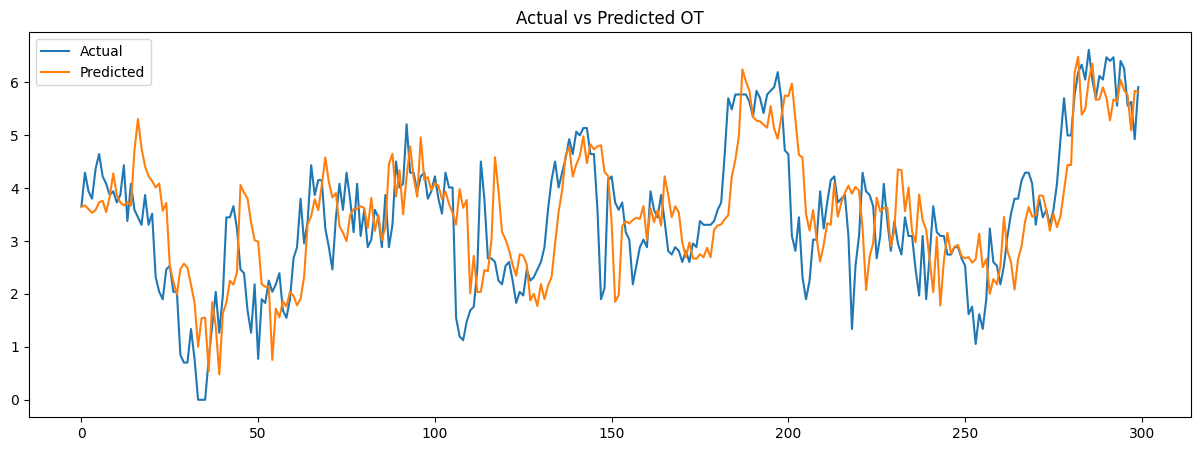

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))

plt.plot(
    y_test.values[:300],
    label="Actual"
)

plt.plot(
    pred[:300],
    label="Predicted"
)

plt.legend()
plt.title("Actual vs Predicted OT")

plt.show()

In [16]:
importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    by="importance",
    ascending=False
)

print(importance)

    feature  importance
7   OT_lag1    0.970958
6      hour    0.008455
9  OT_lag24    0.003767
2      MUFL    0.003332
8   OT_lag3    0.003272
1      HULL    0.003126
0      HUFL    0.002024
3      MULL    0.001755
5      LULL    0.001678
4      LUFL    0.001634
